# 01. Data Preprocessing, Exploratory Data Analysis & Feature Engineering
**Early-Stage Parkinson's Disease Detection via Keystroke Dynamics**

**Dataset:** Tappy Keystroke Dataset (PhysioNet)
**Objective:** Process raw keystroke dynamics from in-the-wild home computer use, engineer temporal/statistical/asymmetry features, and visualize differences between healthy subjects and Parkinson's Disease patients.


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
import warnings
warnings.filterwarnings('ignore')

# Set styling for top-tier EDA
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})


## 1. Data Ingestion: User Metadata
First, we parse the 227 text files containing the user metadata (demographics, PD status, etc.) into a structured Pandas DataFrame.


In [ ]:
user_files_path = r'../Dataset/tappy-keystroke-data-1.0.0/Archived-users/Archived users/*.txt'
user_files = glob.glob(user_files_path)

user_data = []
for file in user_files:
    user_id = os.path.basename(file).split('_')[1].replace('.txt', '')
    user_dict = {'UserID': user_id}
    with open(file, 'r', encoding='utf-8') as f:
        for line in f:
            if ':' in line:
                key, val = line.strip().split(':', 1)
                user_dict[key.strip()] = val.strip()
    user_data.append(user_dict)

df_users = pd.DataFrame(user_data)

# Clean Target Variable (Parkinsons: True -> 1, False -> 0)
df_users = df_users[df_users['Parkinsons'].isin(['True', 'False'])].copy()
df_users['Class'] = df_users['Parkinsons'].apply(lambda x: 1 if x == 'True' else 0)

# Clean Gender and Age
df_users['Gender'] = df_users['Gender'].replace({'------': np.nan})
df_users['BirthYear'] = pd.to_numeric(df_users['BirthYear'], errors='coerce')
df_users['Age'] = 2016 - df_users['BirthYear']

print(f"Loaded {len(df_users)} users.")
df_users.head()


Loaded 227 users.


## 2. Feature Engineering: Processing Keystroke Dynamics
The dataset contains raw TSV logs of keystrokes. We iterate over the data files for each user and compute **aggregated statistical features** (mean, std, skewness, kurtosis) for their keystroke hold times and transition latencies. This transforms massive, noisy time-series data into a clean, tabular format suitable for Machine Learning.


In [ ]:
data_files_path = r'../Dataset/tappy-keystroke-data-1.0.0/Archived-Data/Tappy Data/*.txt'
data_files = glob.glob(data_files_path)

from collections import defaultdict
user_data_files = defaultdict(list)
for file in data_files:
    user_id = os.path.basename(file).split('_')[0]
    user_data_files[user_id].append(file)

col_names = ['UserID', 'Date', 'Time', 'Hand', 'HoldTime', 'Direction', 'Latency1', 'Latency2', 'Unknown']

features_list = []

print("Processing keystrokes and engineering features (this may take a minute)...")
for user_id, files in user_data_files.items():
    dfs = []
    for f in files:
        try:
            temp_df = pd.read_csv(f, sep='\t', names=col_names, engine='python', on_bad_lines='skip')
            dfs.append(temp_df)
        except Exception:
            continue

    if not dfs: continue
    df_keys = pd.concat(dfs, ignore_index=True)

    # ------------------ Data Cleaning ------------------
    df_keys['HoldTime'] = pd.to_numeric(df_keys['HoldTime'], errors='coerce')
    df_keys['Latency1'] = pd.to_numeric(df_keys['Latency1'], errors='coerce')
    df_keys.dropna(subset=['HoldTime'], inplace=True)

    # Filter anomalous keystrokes
    df_keys = df_keys[df_keys['HoldTime'] < 2000]

    if len(df_keys) < 100:
        continue

    # ------------------ Feature Extraction ------------------
    user_features = {'UserID': user_id, 'Total_Keystrokes': len(df_keys)}

    for hand in ['L', 'R']:
        hand_data = df_keys[df_keys['Hand'] == hand]['HoldTime']
        if len(hand_data) > 10:
            user_features[f'HoldTime_{hand}_Mean'] = hand_data.mean()
            user_features[f'HoldTime_{hand}_Std'] = hand_data.std()
            user_features[f'HoldTime_{hand}_Skew'] = skew(hand_data)
            user_features[f'HoldTime_{hand}_Kurt'] = kurtosis(hand_data)

    df_latency = df_keys.dropna(subset=['Latency1'])
    df_latency = df_latency[df_latency['Latency1'] < 2000]

    for direction in ['LL', 'RR', 'LR', 'RL']:
        dir_data = df_latency[df_latency['Direction'] == direction]['Latency1']
        if len(dir_data) > 10:
            user_features[f'Latency_{direction}_Mean'] = dir_data.mean()
            user_features[f'Latency_{direction}_Std'] = dir_data.std()
            user_features[f'Latency_{direction}_Skew'] = skew(dir_data)

    if 'HoldTime_L_Mean' in user_features and 'HoldTime_R_Mean' in user_features:
        user_features['HoldTime_Asymmetry'] = abs(user_features['HoldTime_L_Mean'] - user_features['HoldTime_R_Mean'])

    features_list.append(user_features)

df_features = pd.DataFrame(features_list)
print(f"Engineered features for {len(df_features)} users.")


Processing keystrokes and engineering features (this may take a minute)...
Engineered features for 226 users.


## 3. Merging the Final Dataset
We merge our target labels (`Class`, `Age`, `Gender`) with the newly engineered mathematical features.


In [ ]:
df_final = pd.merge(df_users[['UserID', 'Class', 'Age', 'Gender']], df_features, on='UserID', how='inner')
df_final.fillna(df_final.mean(numeric_only=True), inplace=True)
print(f"Final Dataset Shape: {df_final.shape}")
df_final.head()


Final Dataset Shape: (192, 26)


## 4. Exploratory Data Analysis (EDA)
EDA visually validates our engineered features before moving into Phase 4 (Machine Learning).


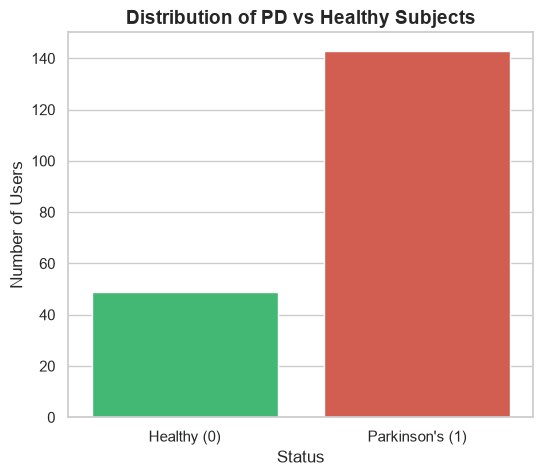

In [ ]:
plt.figure(figsize=(6,5))
ax = sns.countplot(x='Class', data=df_final, palette=['#2ECC71', '#E74C3C'])
ax.set_xticklabels(['Healthy (0)', 'Parkinson\'s (1)'])
plt.title("Distribution of PD vs Healthy Subjects", fontsize=14, weight='bold')
plt.ylabel("Number of Users")
plt.xlabel("Status")
plt.show()


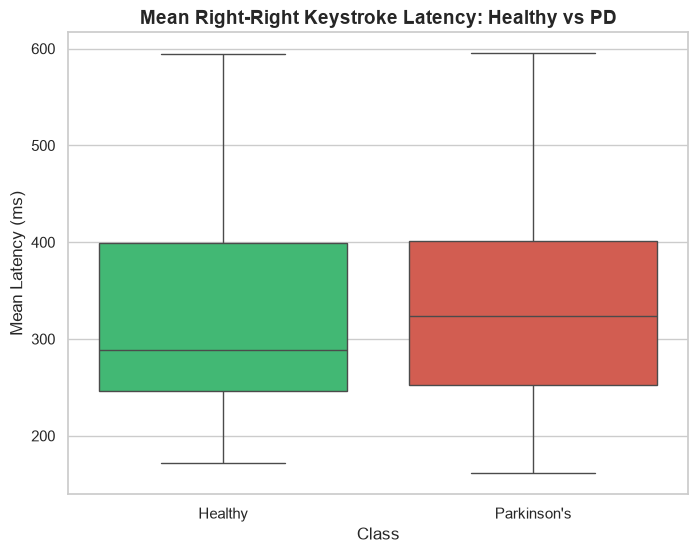

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(x='Class', y='Latency_RR_Mean', data=df_final, palette=['#2ECC71', '#E74C3C'])
plt.title("Mean Right-Right Keystroke Latency: Healthy vs PD", fontsize=14, weight='bold')
plt.xticks([0, 1], ['Healthy', 'Parkinson\'s'])
plt.ylabel("Mean Latency (ms)")
plt.show()


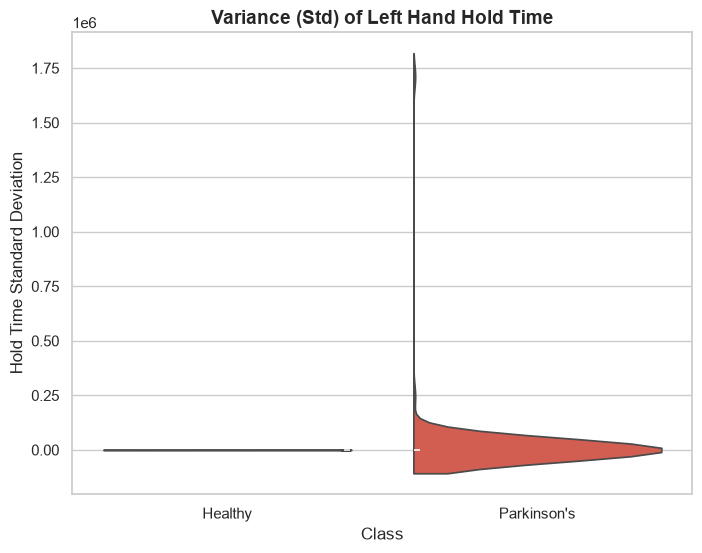

In [ ]:
plt.figure(figsize=(8,6))
sns.violinplot(x='Class', y='HoldTime_L_Std', data=df_final, palette=['#2ECC71', '#E74C3C'], split=True)
plt.title("Variance (Std) of Left Hand Hold Time", fontsize=14, weight='bold')
plt.xticks([0, 1], ['Healthy', 'Parkinson\'s'])
plt.ylabel("Hold Time Standard Deviation")
plt.show()


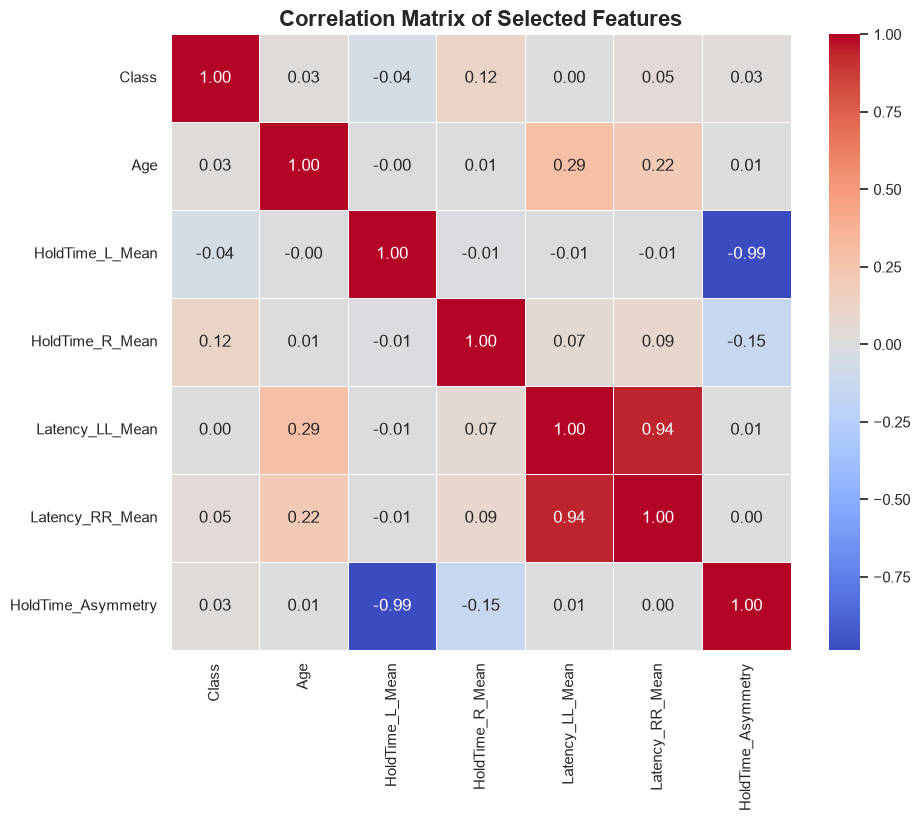

In [ ]:
cols_to_correlate = ['Class', 'Age', 'HoldTime_L_Mean', 'HoldTime_R_Mean', 'Latency_LL_Mean', 'Latency_RR_Mean', 'HoldTime_Asymmetry']
corr = df_final[cols_to_correlate].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title("Correlation Matrix of Selected Features", fontsize=16, weight='bold')
plt.show()


## 5. Exporting Processed Data for Phase 4
We save the highly-cleaned dataset into a CSV file.


In [ ]:
output_path = r'../Phase 3/Processed_Data/processed_dataset.csv'
df_final.to_csv(output_path, index=False)
print(f"Successfully saved clean dataset to: {output_path}")


Successfully saved clean dataset to: ../Phase 3/Processed_Data/processed_dataset.csv
